In [39]:

import pandas as pd
import numpy as np
import os

# Load original dataset
df = pd.read_csv("../data/Bengaluru_House_Data.csv")

# Remove unnecessary columns
df.drop(columns=["availability", "society"], inplace=True)

# Handle missing values
df["size"] = df["size"].fillna("0").str.split().str[0].astype(int)
df["size"] = df["size"].replace(0, df["size"].median())

df["bath"] = df["bath"].fillna(df["bath"].median())
df["balcony"] = df["balcony"].fillna(df["balcony"].median())

df.dropna(inplace=True)

# Convert total_sqft ranges to numeric values
def convert_sqft(value):
    value = str(value).strip()

    try:
        if "-" in value:
            low, high = value.split("-", 1)
            return (float(low) + float(high)) / 2

        return float(value)

    except (ValueError, TypeError):
        return np.nan

df["total_sqft"] = df["total_sqft"].apply(convert_sqft)
df.dropna(subset=["total_sqft"], inplace=True)

# Rename columns
df.rename(
    columns={
        "size": "BHK",
        "price": "price_in_lakhs"
    },
    inplace=True
)

# Clean location names
df["location"] = df["location"].str.strip()

# Group locations having 10 or fewer records
location_counts = df["location"].value_counts()
rare_locations = location_counts[location_counts <= 10].index

df["location"] = df["location"].replace(
    rare_locations, "others"
)

# Remove properties with less than 300 sqft per BHK
df = df[
    (df["total_sqft"] / df["BHK"]) >= 300
].copy()

# Calculate price per square foot for outlier detection
df["price_per_sqft"] = (
    df["price_in_lakhs"] * 100000 / df["total_sqft"]
)

# Remove location-wise price-per-sqft outliers
def remove_location_outliers(data):
    groups = []

    for _, group in data.groupby("location"):
        mean = group["price_per_sqft"].mean()
        std = group["price_per_sqft"].std(ddof=0)

        filtered = group[
            (group["price_per_sqft"] > mean - std) &
            (group["price_per_sqft"] <= mean + std)
        ]

        groups.append(filtered)

    return pd.concat(groups)

df = remove_location_outliers(df)

# Remove BHK outliers based on lower price per sqft
def remove_bhk_outliers(data):
    exclude = []

    for _, location_df in data.groupby("location"):
        stats = location_df.groupby("BHK")[
            "price_per_sqft"
        ].agg(["mean", "count"])

        for bhk, group in location_df.groupby("BHK"):
            previous_bhk = bhk - 1

            if previous_bhk in stats.index:
                previous = stats.loc[previous_bhk]

                if previous["count"] > 5:
                    exclude.extend(
                        group[
                            group["price_per_sqft"] <
                            previous["mean"]
                        ].index
                    )

    return data.drop(index=exclude)

df = remove_bhk_outliers(df)

# Remove temporary column
df.drop(columns=["price_per_sqft"], inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

# Save cleaned dataset
os.makedirs("../data", exist_ok=True)

df.to_csv(
    "../data/cleaned_bengaluru_house_data.csv",
    index=False
)

print("Cleaning completed!")
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nFirst five rows:")
print(df.head())


Cleaning completed!
Dataset shape: (7348, 7)

Missing values:
area_type         0
location          0
BHK               0
total_sqft        0
bath              0
balcony           0
price_in_lakhs    0
dtype: int64

First five rows:
              area_type             location  BHK  total_sqft  bath  balcony  \
0  Super built-up  Area  1st Block Jayanagar    4      2850.0   4.0      1.0   
1  Super built-up  Area  1st Block Jayanagar    3      1630.0   3.0      2.0   
2  Super built-up  Area  1st Block Jayanagar    3      1875.0   2.0      3.0   
3        Built-up  Area  1st Block Jayanagar    3      1200.0   2.0      0.0   
4  Super built-up  Area  1st Block Jayanagar    2      1235.0   2.0      2.0   

   price_in_lakhs  
0           428.0  
1           194.0  
2           235.0  
3           130.0  
4           148.0  


In [40]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Separate input features and target
X = df.drop(columns=["price_in_lakhs"])
y = df["price_in_lakhs"]

# Column groups
categorical_cols = ["area_type", "location"]
numerical_cols = ["BHK", "total_sqft", "bath", "balcony"]

# Preprocessing
preprocessor = ColumnTransformer([
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_cols
    ),
    (
        "numerical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numerical_cols
    )
])

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0
)

# Models
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE (lakhs)": round(mae, 2),
        "RMSE (lakhs)": round(rmse, 2),
        "R² Score": round(r2, 4)
    })

results_df = pd.DataFrame(results)

print("Model Evaluation Results")
print(results_df.to_string(index=False))


Model Evaluation Results
            Model  MAE (lakhs)  RMSE (lakhs)  R² Score
Linear Regression        18.65         34.75    0.8770
    Random Forest        17.56         47.72    0.7679


In [41]:

import os
import joblib

# Select the model based on evaluation results
best_model = trained_models["Linear Regression"]

# Create models folder
os.makedirs("../models", exist_ok=True)

# Save complete pipeline
joblib.dump(
    best_model,
    "../models/house_price_model.pkl"
)

print("Final model: Linear Regression")
print("Saved to: ../models/house_price_model.pkl")


Final model: Linear Regression
Saved to: ../models/house_price_model.pkl


In [42]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load cleaned dataset
df = pd.read_csv("../data/cleaned_bengaluru_house_data.csv")

X = df.drop(columns=["price_in_lakhs"])
y = df["price_in_lakhs"]

categorical_cols = ["area_type", "location"]
numerical_cols = ["BHK", "total_sqft", "bath", "balcony"]

# Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

preprocessor = ColumnTransformer([
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_cols),

    ("numerical",
     Pipeline([
         ("imputer", SimpleImputer(strategy="median")),
         ("scaler", StandardScaler())
     ]),
     numerical_cols)
])

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

baseline_results = []
baseline_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    baseline_models[name] = pipeline

    baseline_results.append({
        "Model": name,
        "MAE (lakhs)": round(
            mean_absolute_error(y_test, predictions), 2
        ),
        "RMSE (lakhs)": round(
            np.sqrt(mean_squared_error(y_test, predictions)), 2
        ),
        "R² Score": round(
            r2_score(y_test, predictions), 4
        )
    })

baseline_results_df = pd.DataFrame(baseline_results)
print(baseline_results_df.to_string(index=False))


            Model  MAE (lakhs)  RMSE (lakhs)  R² Score
Linear Regression        18.65         34.75    0.8770
    Random Forest        17.56         47.72    0.7679


In [43]:
comparison = pd.DataFrame({
    "Actual Price (lakhs)": y_test,
    "Predicted Price (lakhs)": predictions
})

display(comparison.head(10))

,Actual Price (lakhs),Predicted Price (lakhs)
768,58.00,47.453417
2412,97.00,76.608307
5329,80.00,77.503633
39,69.00,71.579633
1748,64.50,73.976063
773,68.00,66.890400
4801,43.00,30.625937
979,135.00,122.692133
1143,32.49,39.372844
4656,225.00,193.982727


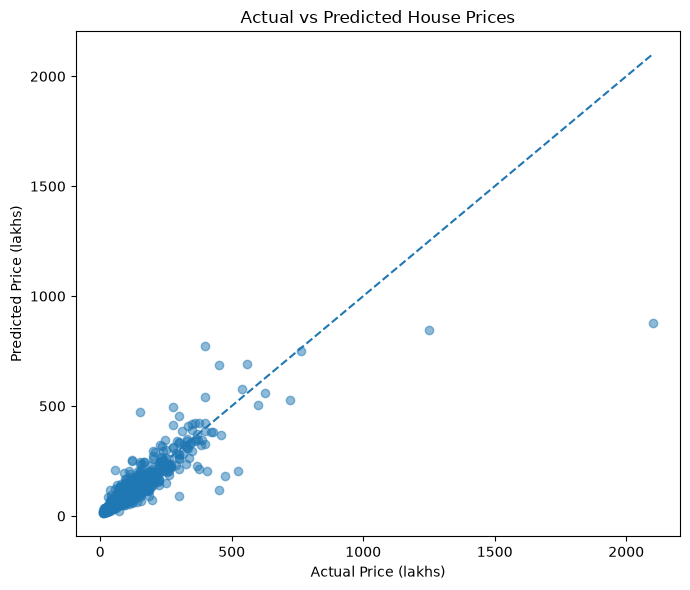

In [44]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, predictions, alpha=0.5)

# Ideal predictions lie on this line
minimum = min(y_test.min(), predictions.min())
maximum = max(y_test.max(), predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Price (lakhs)")
plt.ylabel("Predicted Price (lakhs)")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()


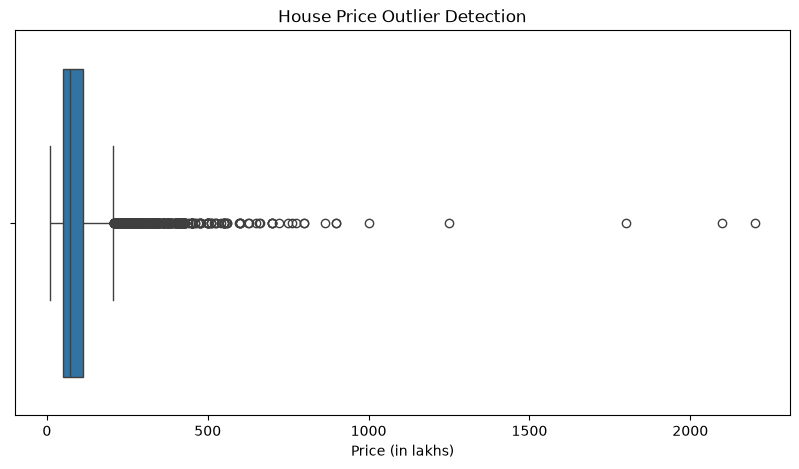

count    7348.00000
mean       99.12409
std        93.40081
min        10.00000
90%       185.00000
95%       265.00000
99%       430.00000
max      2200.00000
Name: price_in_lakhs, dtype: float64


In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.boxplot(x=df["price_in_lakhs"])
plt.title("House Price Outlier Detection")
plt.xlabel("Price (in lakhs)")
plt.show()

print(df["price_in_lakhs"].describe(
    percentiles=[0.90, 0.95, 0.99]
))

In [46]:
price_limit = df["price_in_lakhs"].quantile(0.99)

df_filtered = df[df["price_in_lakhs"] <= price_limit].copy()

print("Original rows:", len(df))
print("Rows after filtering:", len(df_filtered))
print("Price limit:", round(price_limit, 2), "lakhs")
print("Rows removed:", len(df) - len(df_filtered))

Original rows: 7348
Rows after filtering: 7275
Price limit: 430.0 lakhs
Rows removed: 73


In [47]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Features and target after price filtering
X_filtered = df_filtered.drop(columns=["price_in_lakhs"])
y_filtered = df_filtered["price_in_lakhs"]

# Fresh train-test split
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_filtered,
    y_filtered,
    test_size=0.2,
    random_state=42
)

# Train Linear Regression
filtered_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

filtered_model.fit(X_train_f, y_train_f)

# Evaluate
predictions_f = filtered_model.predict(X_test_f)

print("Linear Regression after price filtering")
print("MAE:", round(mean_absolute_error(y_test_f, predictions_f), 2), "lakhs")
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_f, predictions_f)), 2), "lakhs")
print("R²:", round(r2_score(y_test_f, predictions_f), 4))


Linear Regression after price filtering
MAE: 16.22 lakhs
RMSE: 26.48 lakhs
R²: 0.8647


In [48]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Use the original cleaned dataset
X = df.drop(columns=["price_in_lakhs"])
y = df["price_in_lakhs"]

# Create one common split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Keep only test properties within the price range
test_mask = y_test <= 430

X_test_common = X_test.loc[test_mask]
y_test_common = y_test.loc[test_mask]

# Model 1: Train on all training prices
model_original = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

model_original.fit(X_train, y_train)
pred_original = model_original.predict(X_test_common)

# Model 2: Train only on properties priced at or below 430 lakhs
train_mask = y_train <= 430

model_filtered = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

model_filtered.fit(
    X_train.loc[train_mask],
    y_train.loc[train_mask]
)
pred_filtered = model_filtered.predict(X_test_common)

# Compare on exactly the same test properties
results = []

for name, predictions in [
    ("Original Linear Regression", pred_original),
    ("Filtered-training Linear Regression", pred_filtered)
]:
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test_common, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_common, predictions)),
        "R2": r2_score(y_test_common, predictions)
    })

results_df = pd.DataFrame(results)
print("Common test rows:", len(y_test_common))
display(results_df.round(3))


Common test rows: 1452


,Model,MAE,RMSE,R2
0,Original Linear Regression,16.764,26.004,0.868
1,Filtered-training Linear Regression,16.389,25.878,0.870


In [49]:

import os
import joblib
import numpy as np

# Create the models folder if it doesn't exist
os.makedirs("../models", exist_ok=True)

# Save the final model
model_path = "../models/house_price_model.pkl"
joblib.dump(model_filtered, model_path)

print("Model saved successfully!")
print("Location:", model_path)


Model saved successfully!
Location: ../models/house_price_model.pkl


In [50]:

# Load the saved model
loaded_model = joblib.load("../models/house_price_model.pkl")

# Predict using a few test rows
sample_data = X_test_common.head(5)
predictions = loaded_model.predict(sample_data)

print("Sample predictions (in lakhs):")
for i, price in enumerate(predictions, start=1):
    print(f"House {i}: ₹{price:.2f} lakhs")

# Verify predictions match the original pipeline
original_predictions = model_filtered.predict(sample_data)

print(
    "\nVerification passed:",
    np.allclose(predictions, original_predictions)
)


Sample predictions (in lakhs):
House 1: ₹44.73 lakhs
House 2: ₹216.91 lakhs
House 3: ₹51.63 lakhs
House 4: ₹141.96 lakhs
House 5: ₹56.29 lakhs

Verification passed: True


In [51]:

import os
import joblib
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Keep properties within our selected price range
df_final = df[df["price_in_lakhs"] <= 430].copy()

# Separate features and target
X_final = df_final.drop(columns=["price_in_lakhs"])
y_final = df_final["price_in_lakhs"]

# Build the final pipeline
final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

# Train on all eligible cleaned records
final_model.fit(X_final, y_final)

# Save model from the notebooks folder
os.makedirs("../models", exist_ok=True)
model_path = "../models/house_price_model.pkl"

joblib.dump(final_model, model_path)

print("Final model trained and saved!")
print("Eligible training rows:", len(X_final))
print("Features:", list(X_final.columns))
print("Saved to:", model_path)


Final model trained and saved!
Eligible training rows: 7275
Features: ['area_type', 'location', 'BHK', 'total_sqft', 'bath', 'balcony']
Saved to: ../models/house_price_model.pkl


In [52]:

# Reload the model from disk
loaded_model = joblib.load("../models/house_price_model.pkl")

# Test with a few real rows
sample_data = X_final.head(5)
predictions = loaded_model.predict(sample_data)

print("Saved model loaded successfully!")
print("\nSample predictions:")

for i, price in enumerate(predictions, start=1):
    print(f"House {i}: ₹{price:.2f} lakhs")

print("\nAll predictions finite:",
      all(pd.notna(predictions)))


Saved model loaded successfully!

Sample predictions:
House 1: ₹339.17 lakhs
House 2: ₹247.88 lakhs
House 3: ₹262.68 lakhs
House 4: ₹208.15 lakhs
House 5: ₹216.51 lakhs

All predictions finite: True


In [53]:
import os
import pandas as pd

# Keep properties priced at ₹430 lakhs or below
df_filtered = df[df["price_in_lakhs"] <= 430].copy()

print("Original cleaned dataset:", df.shape)
print("Filtered dataset:", df_filtered.shape)
print("Maximum price:", df_filtered["price_in_lakhs"].max())

# Save the filtered dataset for the application
os.makedirs("../data", exist_ok=True)

df_filtered.to_csv(
    "../data/cleaned_bengaluru_house_data.csv",
    index=False
)

print("Filtered dataset saved successfully!")

Original cleaned dataset: (7348, 7)
Filtered dataset: (7275, 7)
Maximum price: 430.0
Filtered dataset saved successfully!


In [54]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Split the original cleaned dataset before filtering
X = df.drop(columns=["price_in_lakhs"])
y = df["price_in_lakhs"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Apply the same ₹430 lakh limit to each partition
train_mask = y_train <= 430
test_mask = y_test <= 430

X_train_filtered = X_train.loc[train_mask]
y_train_filtered = y_train.loc[train_mask]

X_test_filtered = X_test.loc[test_mask]
y_test_filtered = y_test.loc[test_mask]

# Train a fresh model
filtered_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

filtered_model.fit(X_train_filtered, y_train_filtered)

# Evaluate on eligible, held-out test properties
predictions = filtered_model.predict(X_test_filtered)

print("Training rows:", len(X_train_filtered))
print("Testing rows:", len(X_test_filtered))
print("MAE:", round(mean_absolute_error(y_test_filtered, predictions), 2), "lakhs")
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_filtered, predictions)), 2), "lakhs")
print("R²:", round(r2_score(y_test_filtered, predictions), 4))

Training rows: 5823
Testing rows: 1452
MAE: 16.39 lakhs
RMSE: 25.88 lakhs
R²: 0.8697


In [55]:
import joblib

X_final = df_filtered.drop(columns=["price_in_lakhs"])
y_final = df_filtered["price_in_lakhs"]

final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LinearRegression())
])

final_model.fit(X_final, y_final)

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model,
    "../models/house_price_model.pkl"
)

print("Final filtered model saved successfully!")
print("Training records:", len(X_final))
print("Maximum training price:", y_final.max(), "lakhs")

Final filtered model saved successfully!
Training records: 7275
Maximum training price: 430.0 lakhs
